# Sentiment Analysis with VADER

VADER (Valence Aware Dictionary and Sentiment Reasoner) is a lexicon and rule-based sentiment analysis tool that is specifically attuned to sentiments expressed in social media. 


In [138]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('bmh')
import seaborn as sns
!pip install vaderSentiment
from nltk.sentiment.vader import SentimentIntensityAnalyzer

In [139]:
analyser = SentimentIntensityAnalyzer()

## Importing `clean_df`

In [140]:
clean_lib_df = pd.read_csv("C:/Users/samik/Downloads/SMM/Paper2/LiberalsData/Preprocessed_Lib_Comments.csv.csv")
clean_con_df = pd.read_csv("C:/Users/samik/Downloads/SMM/Paper2/ConservativesData/Preprocessed_Con_Comments.csv")

## Sentiment of Reddit Post Comments

In [141]:
# function to calculate polarity scores
pol = lambda x: analyser.polarity_scores(x)


In [142]:
# creating new column 'polarity' in clean_df
#clean_lib_df['polarity'] = clean_lib_df['Text'].apply(pol)
#clean_con_df['polarity'] = clean_con_df['Text'].apply(pol)

#clean_lib_df[['neg', 'neu', 'pos', 'compound']] = clean_lib_df['Text'].apply(lambda x: pd.Series(analyser.polarity_scores(x)))

# Safely expand polarity scores into 4 columns
sentiment_scores = clean_lib_df['Text'].apply(lambda x: pd.Series(analyser.polarity_scores(x)))
sentiment_scores.columns = ['neg', 'neu', 'pos', 'compound']

# Add the columns to your main dataframe
clean_lib_df = pd.concat([clean_lib_df, sentiment_scores], axis=1)

In [143]:
# Filter out non-string rows if needed
clean_con_df = clean_con_df[clean_con_df['Text'].apply(lambda x: isinstance(x, str))]

# Apply VADER sentiment analysis and expand the dictionary
con_sentiment_scores = clean_con_df['Text'].apply(lambda x: pd.Series(analyser.polarity_scores(x)))
con_sentiment_scores.columns = ['neg', 'neu', 'pos', 'compound']

# Merge scores into the main conservative dataframe
clean_con_df = pd.concat([clean_con_df, con_sentiment_scores], axis=1)


In [144]:
# checking that worked
clean_lib_df.head(10)

,Author,Text,Date,Score,neg,neu,pos,compound
0,EndsWithJusSayin,press secretary karoline leavitt told reporter...,2025-03-06 15:11:45+00:00,19805,0.071,0.929,0.000,-0.2960
1,SillyGoatGruff,fuck him fuck her and fuck that canadians will...,2025-03-06 16:44:50+00:00,2685,0.212,0.751,0.036,-0.9408
2,New_Zorgo39,usa has lost every credibility it once had ser...,2025-03-06 15:11:03+00:00,1621,0.381,0.619,0.000,-0.7506
3,Revolutionary-Swan77,relationship hasnt been this bad with canada s...,2025-03-06 16:49:26+00:00,453,0.273,0.727,0.000,-0.6280
4,overbarking,chatty cathy doll pull her string and shell sa...,2025-03-06 15:05:54+00:00,164,0.000,0.894,0.106,0.0772
5,EnvironmentalEye4537,i have absolutely no doubt in my mind trump wa...,2025-03-06 15:04:15+00:00,824,0.293,0.685,0.023,-0.9707
6,cablguy104,if they want canada theyd have to come and tak...,2025-03-06 16:49:38+00:00,446,0.239,0.726,0.035,-0.8625
7,Cactusfan86,obviously this is a minor thing in the grand s...,2025-03-06 17:22:12+00:00,227,0.067,0.833,0.099,0.1804
8,ChezDudu,this isnt the real goal the real goal is selfe...,2025-03-06 16:54:09+00:00,61,0.000,0.807,0.193,0.7717
9,Fancy-Ambassador6160,hey you guys remember learning about nazi germ...,2025-03-06 17:33:23+00:00,54,0.313,0.613,0.074,-0.9496


In [145]:

import os
# Save cleaned file
output_path1 = "C:/Users/samik/Downloads/SMM/Paper2/LiberalsData/Vader_score_Lib.csv"
os.makedirs(os.path.dirname(output_path1), exist_ok=True)
clean_lib_df.to_csv(output_path1, index=False)

In [146]:
# checking that worked
clean_con_df.head(10)

,Author,Text,Date,Score,neg,neu,pos,compound
0,otakuzod,what is trumps endgame with this? was there so...,2025-03-04 18:11:52+00:00,434,0.000,1.000,0.000,0.0000
1,[deleted],the white house needs to explain the reasoning...,2025-03-04 18:37:14+00:00,159,0.067,0.787,0.145,0.8094
2,Communalbuttplug,trumps just announced for every retaliatory ta...,2025-03-04 18:00:06+00:00,195,0.000,0.906,0.094,0.6124
3,[deleted],i just dont know why its necessary to pick fig...,2025-03-04 18:52:01+00:00,158,0.123,0.770,0.107,-0.1655
4,Lifeisagreatteacher,math canada annual trade surplus with us 108 b...,2025-03-04 18:11:19+00:00,271,0.070,0.838,0.091,0.5632
5,HKatzOnline,if tariffs are dumb why did canada have such l...,2025-03-04 18:39:30+00:00,88,0.191,0.809,0.000,-0.5106
6,Mehnard,what did trudeau say about the dairy tariffs c...,2025-03-04 20:42:41+00:00,22,0.000,1.000,0.000,0.0000
7,GeneticsGuy,if tariffs are so dumb why does canada already...,2025-03-04 19:08:34+00:00,50,0.116,0.794,0.090,-0.2362
8,Opening-Citron2733,he calls tariffs dumb but they have like a 200...,2025-03-04 18:05:05+00:00,202,0.298,0.562,0.140,-0.5647
9,Bramse-TFK,tariffs are very dumb except for the ones we h...,2025-03-04 20:30:58+00:00,16,0.162,0.762,0.076,-0.6333


In [147]:
output_path2 = "C:/Users/samik/Downloads/SMM/Paper2/ConservativesData/Vader_score_Con.csv"
os.makedirs(os.path.dirname(output_path2), exist_ok=True)
clean_con_df.to_csv(output_path2, index=False)

## Parsing Out Polarity Score

In [148]:
# Apply VADER to each row of the liberal dataset
clean_lib_df[['neg', 'neu', 'pos', 'compound']] = clean_lib_df['Text'].apply(lambda x: pd.Series(analyser.polarity_scores(x)))

# Apply VADER to each row of the conservative dataset
clean_con_df[['neg', 'neu', 'pos', 'compound']] = clean_con_df['Text'].apply(lambda x: pd.Series(analyser.polarity_scores(x)))

In [149]:
clean_lib_df.head()

,Author,Text,Date,Score,neg,neu,pos,compound
0,EndsWithJusSayin,press secretary karoline leavitt told reporter...,2025-03-06 15:11:45+00:00,19805,0.071,0.929,0.000,-0.2960
1,SillyGoatGruff,fuck him fuck her and fuck that canadians will...,2025-03-06 16:44:50+00:00,2685,0.212,0.751,0.036,-0.9408
2,New_Zorgo39,usa has lost every credibility it once had ser...,2025-03-06 15:11:03+00:00,1621,0.381,0.619,0.000,-0.7506
3,Revolutionary-Swan77,relationship hasnt been this bad with canada s...,2025-03-06 16:49:26+00:00,453,0.273,0.727,0.000,-0.6280
4,overbarking,chatty cathy doll pull her string and shell sa...,2025-03-06 15:05:54+00:00,164,0.000,0.894,0.106,0.0772


In [150]:
clean_con_df.head()

,Author,Text,Date,Score,neg,neu,pos,compound
0,otakuzod,what is trumps endgame with this? was there so...,2025-03-04 18:11:52+00:00,434,0.000,1.000,0.000,0.0000
1,[deleted],the white house needs to explain the reasoning...,2025-03-04 18:37:14+00:00,159,0.067,0.787,0.145,0.8094
2,Communalbuttplug,trumps just announced for every retaliatory ta...,2025-03-04 18:00:06+00:00,195,0.000,0.906,0.094,0.6124
3,[deleted],i just dont know why its necessary to pick fig...,2025-03-04 18:52:01+00:00,158,0.123,0.770,0.107,-0.1655
4,Lifeisagreatteacher,math canada annual trade surplus with us 108 b...,2025-03-04 18:11:19+00:00,271,0.070,0.838,0.091,0.5632


## Average Polarity Scores for Liberals & Conservatives

In [151]:
lib_scores_df = clean_lib_df[['pos', 'neu', 'neg', 'compound']].mean().reset_index()
lib_scores_df.columns = ['polarity_type', 'liberal_avg_score']

con_scores_df = clean_con_df[['pos', 'neu', 'neg', 'compound']].mean().reset_index()
con_scores_df.columns = ['polarity_type', 'conservative_avg_score']


In [152]:
lib_scores_df.head()

,polarity_type,liberal_avg_score
0,pos,0.089424
1,neu,0.773180
2,neg,0.137392
3,compound,-0.184317


In [153]:
con_scores_df.head()

,polarity_type,conservative_avg_score
0,pos,0.105848
1,neu,0.783976
2,neg,0.110176
3,compound,0.012748


In [154]:
combined_scores = pd.merge(lib_scores_df, con_scores_df, on='polarity_type')


In [155]:
combined_scores.head()

,polarity_type,liberal_avg_score,conservative_avg_score
0,pos,0.089424,0.105848
1,neu,0.773180,0.783976
2,neg,0.137392,0.110176
3,compound,-0.184317,0.012748


## Visualizations

C:\Users\samik\AppData\Local\Temp\ipykernel_20792\3366040902.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(clean_lib_df['compound'], label='Liberals', color='blue', shade=True)
C:\Users\samik\AppData\Local\Temp\ipykernel_20792\3366040902.py:4: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(clean_con_df['compound'], label='Conservatives', color='orange', shade=True)


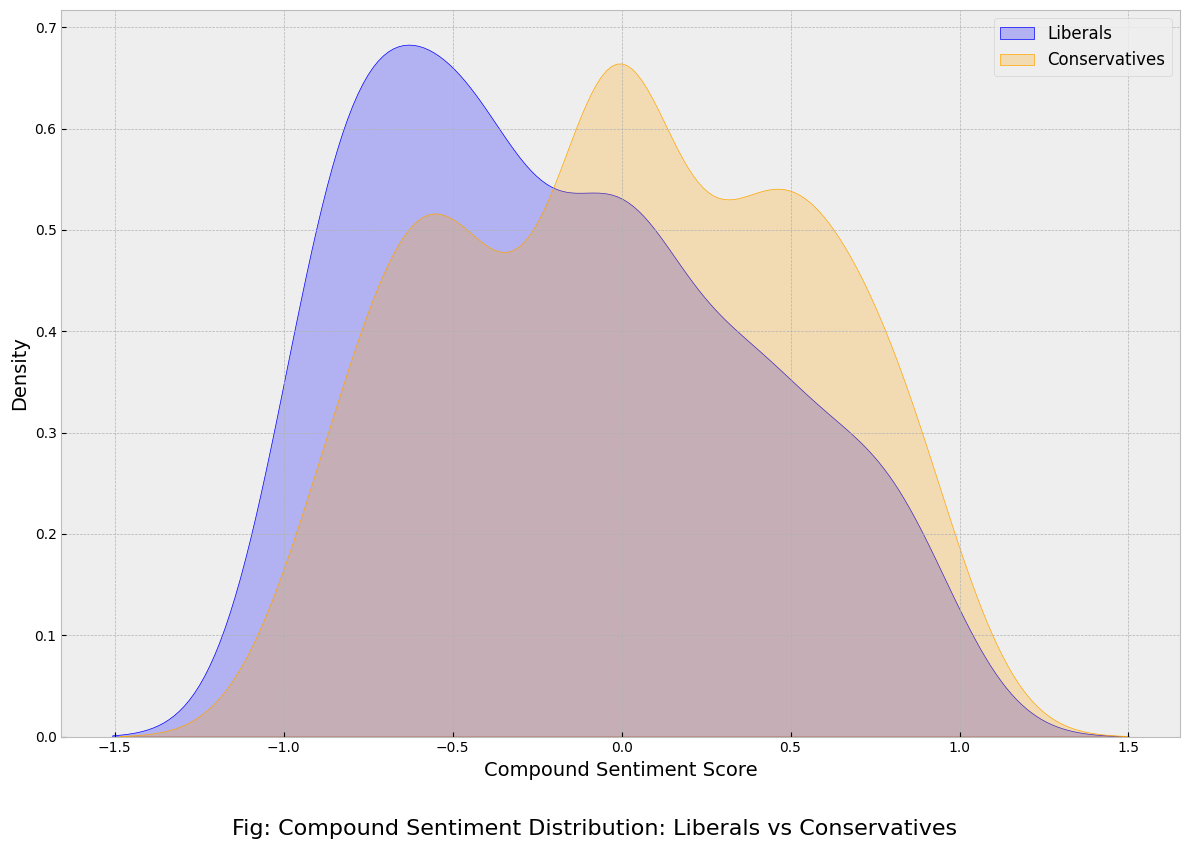

In [156]:
plt.figure(figsize=(12, 8))

sns.kdeplot(clean_lib_df['compound'], label='Liberals', color='blue', shade=True)
sns.kdeplot(clean_con_df['compound'], label='Conservatives', color='orange', shade=True)

plt.xlabel('Compound Sentiment Score', fontsize=14)
plt.ylabel('Density', fontsize=14)
plt.legend(prop={'size': 12})

plt.tight_layout()
plt.figtext(0.5, -0.05, 'Fig: Compound Sentiment Distribution: Liberals vs Conservatives',
            wrap=True, horizontalalignment='center', fontsize=16)

plt.show()


In [158]:
lib_avg = clean_lib_df[['neg', 'neu', 'pos', 'compound']].mean().reset_index()
lib_avg.columns = ['sentiment_type', 'Liberals']

con_avg = clean_con_df[['neg', 'neu', 'pos', 'compound']].mean().reset_index()
con_avg.columns = ['sentiment_type', 'Conservatives']


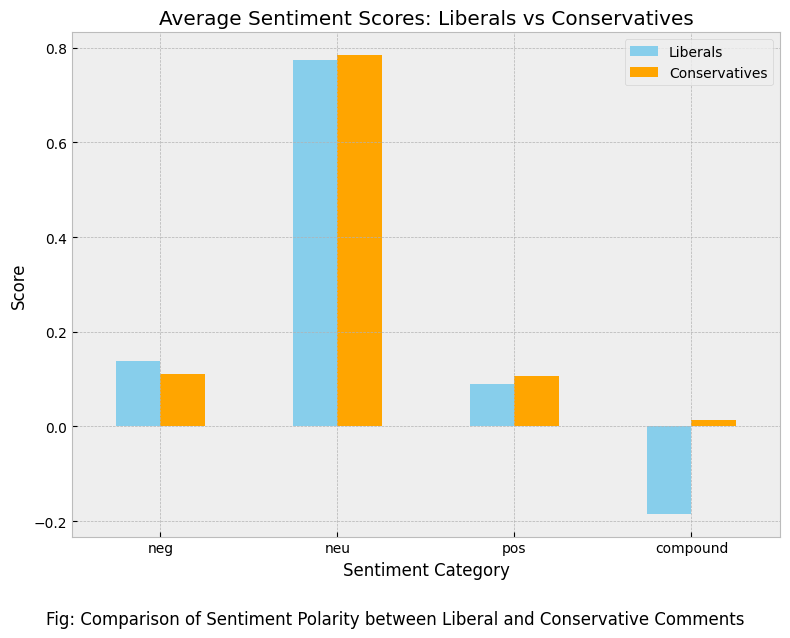

In [163]:
merged_avg = pd.merge(lib_avg, con_avg, on='sentiment_type')

# Plotting
import matplotlib.pyplot as plt

#merged_avg.set_index('sentiment_type').plot(kind='bar', figsize=(8, 6))
ax = merged_avg.set_index('sentiment_type').plot(
    kind='bar',
    figsize=(8, 6),
    color=['skyblue', 'orange']
)
plt.title("Average Sentiment Scores: Liberals vs Conservatives")
plt.ylabel("Score")
plt.xlabel("Sentiment Category")
plt.xticks(rotation=0)
plt.figtext(0.5, -0.05, "Fig: Comparison of Sentiment Polarity between Liberal and Conservative Comments", 
            wrap=True, horizontalalignment='center', fontsize=12)
plt.tight_layout()
plt.show()


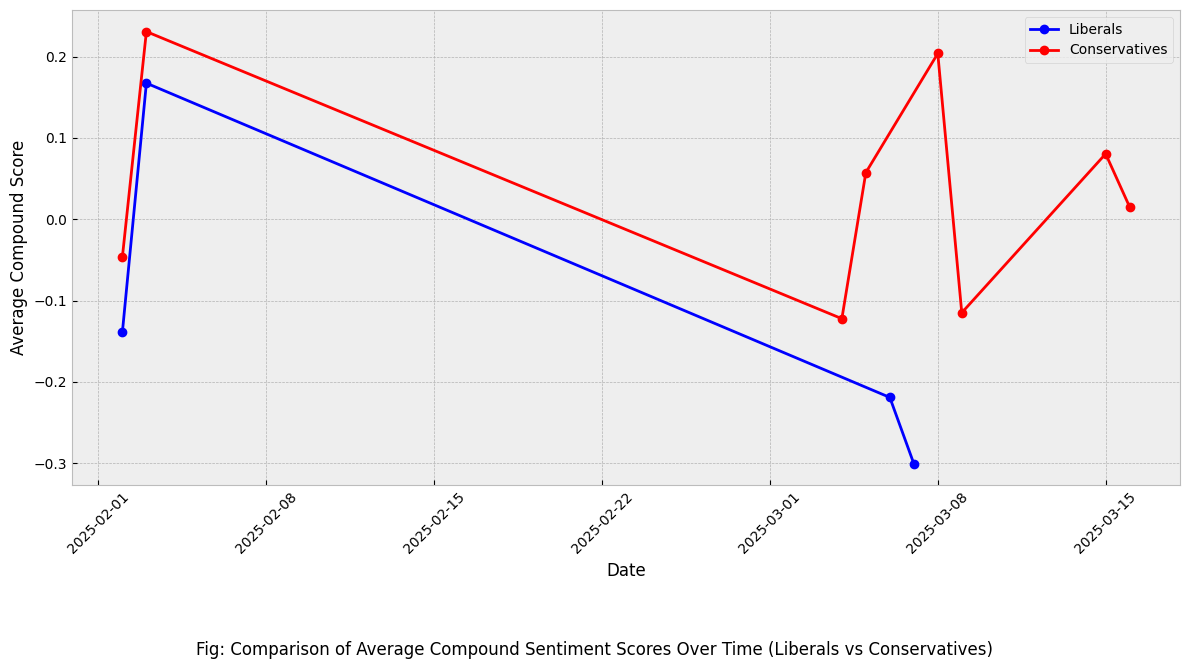

In [160]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the CSV files
lib_df = pd.read_csv('C:/Users/samik/Downloads/SMM/Paper2/LiberalsData/Vader_score_Lib.csv')
con_df = pd.read_csv('C:/Users/samik/Downloads/SMM/Paper2/ConservativesData/Vader_score_Con.csv')

# Convert 'Date' to datetime
lib_df['Date'] = pd.to_datetime(lib_df['Date'])
con_df['Date'] = pd.to_datetime(con_df['Date'])

# Group by date and calculate average compound score
lib_sentiment_trend = lib_df.groupby(lib_df['Date'].dt.date)['compound'].mean()
con_sentiment_trend = con_df.groupby(con_df['Date'].dt.date)['compound'].mean()

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(lib_sentiment_trend, marker='o', label='Liberals', color='blue')
plt.plot(con_sentiment_trend, marker='o', label='Conservatives', color='red')
plt.xlabel('Date')
plt.ylabel('Average Compound Score')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.figtext(0.5, -0.1, 'Fig: Comparison of Average Compound Sentiment Scores Over Time (Liberals vs Conservatives)',
            wrap=True, horizontalalignment='center', fontsize=12)
plt.tight_layout()
plt.show()


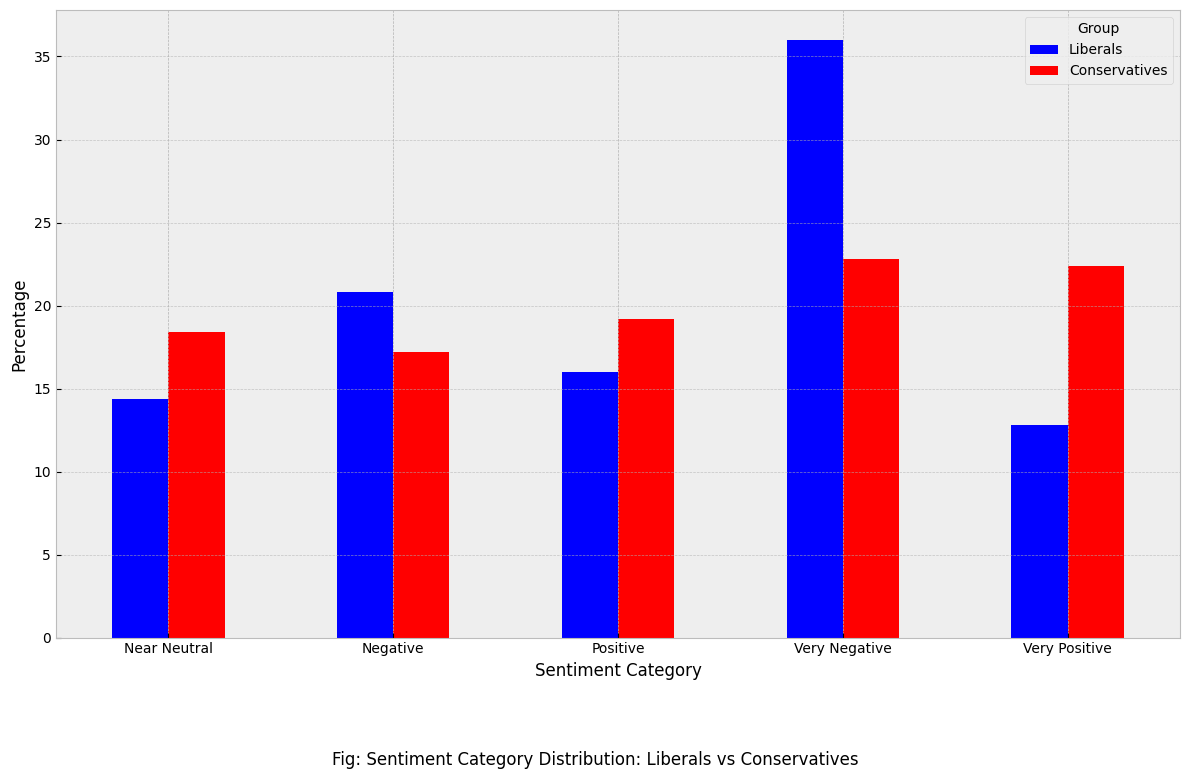

In [161]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the provided liberal and conservative datasets with VADER compound scores
lib_df = pd.read_csv('C:/Users/samik/Downloads/SMM/Paper2/LiberalsData/Vader_score_Lib.csv')
con_df = pd.read_csv('C:/Users/samik/Downloads/SMM/Paper2/ConservativesData/Vader_score_Con.csv')
# Define function for classifying compound scores into categories
def sentiment_category(score):
    if score > 0.5:
        return 'Very Positive'
    elif score > 0.1:
        return 'Positive'
    elif score > -0.1:
        return 'Near Neutral'
    elif score > -0.5:
        return 'Negative'
    else:
        return 'Very Negative'

# Apply sentiment categorization
lib_df['Sentiment_Category'] = lib_df['compound'].apply(sentiment_category)
con_df['Sentiment_Category'] = con_df['compound'].apply(sentiment_category)

# Calculate sentiment distribution percentages
lib_sentiment_percent = lib_df['Sentiment_Category'].value_counts(normalize=True) * 100
con_sentiment_percent = con_df['Sentiment_Category'].value_counts(normalize=True) * 100

# Combine into one dataframe
df_sentiment_comparison = pd.DataFrame({'Liberals': lib_sentiment_percent, 'Conservatives': con_sentiment_percent}).fillna(0)

# Plotting
ax = df_sentiment_comparison.plot(kind='bar', figsize=(12, 7), color=['blue', 'red'])
plt.figtext(0.5, -0.1, 'Fig: Sentiment Category Distribution: Liberals vs Conservatives',
            wrap=True, horizontalalignment='center', fontsize=12)
plt.xlabel('Sentiment Category')
plt.ylabel('Percentage')
plt.xticks(rotation=0)
plt.legend(title='Group')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Show the plot
plt.show()
